In [1]:
# Program Halo Dunia dan Cek Versi R
pesan <- "Halo Dunia! Kernel R di VS Code + Kitty aman 100%"
print(pesan)

# Mengintip versi R yang terinstal di dalam r_env kamu
R.version.string


[1] "Halo Dunia! Kernel R di VS Code + Kitty aman 100%"


[1] "R version 4.5.3 (2026-03-11)"

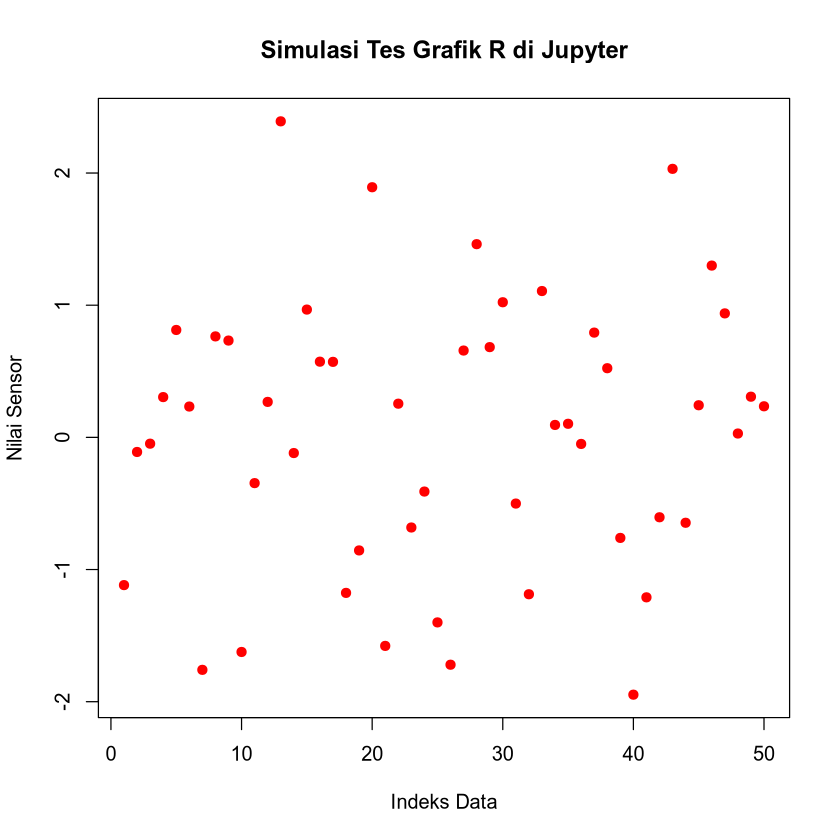

In [2]:
# Menguji performa render grafik interaktif Ryzen 5 5600G
# Membuat plot acak sebanyak 50 titik
data_x <- 1:50
data_y <- rnorm(50)

plot(data_x, data_y, 
     main = "Simulasi Tes Grafik R di Jupyter", 
     col = "red", 
     pch = 19, 
     xlab = "Indeks Data", 
     ylab = "Nilai Sensor")


Generate 500.000 baris data sensor IIoT untuk 33 mesin
-> Memuat

Ryzen Multithreading Check
-> Agregasi data: 0.1324 detik

Render Engine: Tren Grafik dari Ratusan Ribu Baris...
-> Render grafis GGPlot2: 0.3454 detik


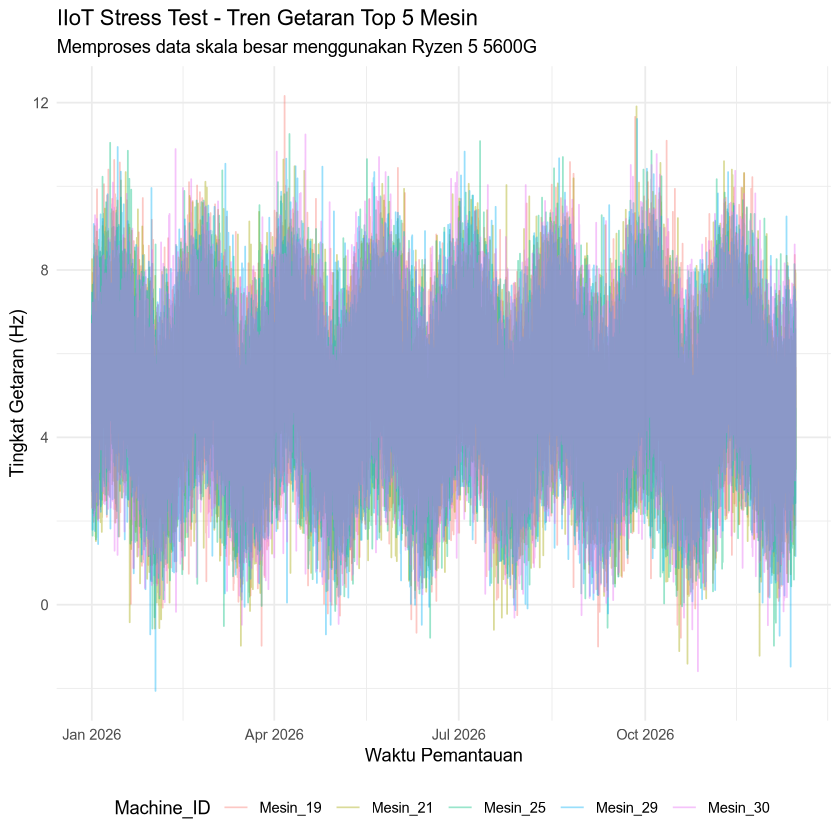

In [7]:
library(data.table)
library(ggplot2)

setDTthreads(percent = 100)

cat("Generate 500.000 baris data sensor IIoT untuk 33 mesin\n")
set.seed(42)
total_baris <- 500000
daftar_mesin <- paste0("Mesin_", sprintf("%02d", 1:33))

df_iiot <- data.table(
  Timestamp = seq(from = as.POSIXct("2026-01-01 00:00:00"), by = "min", length.out = total_baris),
  Machine_ID = sample(daftar_mesin, total_baris, replace = TRUE),
  Vibration = round(rnorm(total_baris, mean = 5, sd = 1.5) + sin(1:total_baris/10000), 2)
)
cat("-> Memuat\n\n")

cat("Ryzen Multithreading Check\n")
tic_agregasi <- Sys.time()
top_mesin <- df_iiot[, .(Rata_Getaran = mean(Vibration)), by = Machine_ID][order(-Rata_Getaran)][1:5, Machine_ID]
df_plot <- df_iiot[Machine_ID %in% top_mesin]
toc_agregasi <- Sys.time()
cat(paste("-> Agregasi data:", round(as.numeric(toc_agregasi - tic_agregasi), 4), "detik\n\n"))

cat("Render Engine: Tren Grafik dari Ratusan Ribu Baris...\n")
tic_plot <- Sys.time()

p <- ggplot(df_plot, aes(x = Timestamp, y = Vibration, color = Machine_ID)) +
  geom_line(alpha = 0.4) + 
  theme_minimal() +
  labs(title = "IIoT Stress Test - Tren Getaran Top 5 Mesin",
       subtitle = "Memproses data skala besar menggunakan Ryzen 5 5600G",
       x = "Waktu Pemantauan", y = "Tingkat Getaran (Hz)") +
  theme(legend.position = "bottom")

print(p)

toc_plot <- Sys.time()
cat(paste("-> Render grafis GGPlot2:", round(as.numeric(toc_plot - tic_plot), 4), "detik\n"))
